In [1]:
import pandas as pd

In [2]:
final_data = pd.read_csv('experiments/full_pipeline/final_data.csv')

In [3]:
fishes = final_data['fish'].unique()

fish_data = final_data.query('fish == @fishes[0]')

In [4]:
from pipeline_utility import get_sequence

In [5]:
earliest_appearances = fish_data.groupby('barcode', as_index = False)['sample'].min()
earliest_appearances

,barcode,sample
0,12D+34_12D+60_NONE_1I+119+A&5D+121_19D+130_4S+...,5
1,12D+34_12D+60_NONE_NONE_3D+143_84D+169_84D+169...,1
2,12D+34_12D+60_NONE_NONE_3D+143_NONE_54D+199_54...,2
3,12D+34_12D+60_NONE_NONE_NONE_NONE_54D+199_54D+...,1
4,1D+38_28D+41_NONE_18D+113_NONE_NONE_54D+199_54...,1
5,1D+38_28D+41_NONE_NONE_NONE_6D+167_54D+199_54D...,7
6,1D+38_28D+41_NONE_NONE_NONE_84D+169_84D+169_84...,1
7,1D+38_28D+41_NONE_NONE_NONE_NONE_54D+199_54D+1...,1
8,1D+38_28D+41_NONE_NONE_NONE_NONE_NONE_NONE_NON...,1
9,3D+37_76I+66+TGTCGTGCAGTCGACTCCATGACAGCAGATACT...,1


In [6]:
import pipeline_utility as pu
reference_seq = pu.BarcodeRemap().zebrafish_reference_sequence

In [7]:
earliest_appearances["sequence"] = earliest_appearances["barcode"].apply(
    lambda bc: get_sequence(bc, ref=reference_seq)
)


In [8]:
earliest_appearances['barcode'].iloc[2]

'12D+34_12D+60_NONE_NONE_3D+143_NONE_54D+199_54D+199_54D+199_NONE'

/opt/anaconda3/envs/weber2/lib/python3.11/site-packages/treedata/_core/read.py:19: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  ANDATA_VERSION = version.parse(ad.__version__)


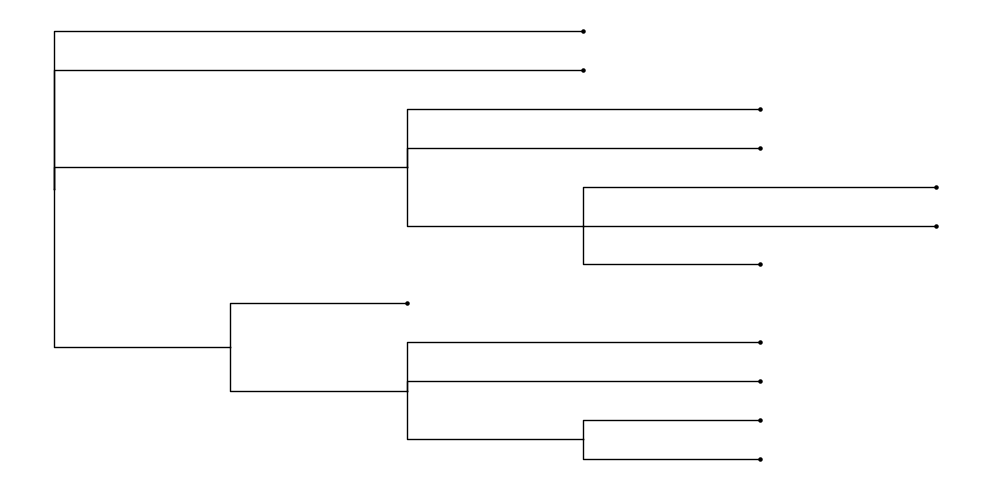

((((barcode_2,barcode_1),barcode_0,barcode_3),barcode_10),((barcode_4,barcode_5,barcode_7),barcode_6,barcode_8),barcode_9,barcode_11);


In [9]:
# pip install cassiopeia-lineage

import pandas as pd
import matplotlib.pyplot as plt
import cassiopeia as cas

df = earliest_appearances.copy()
barcodes = df["barcode"].astype(str)

# Extract the set of irreversible editing events from each barcode.
# "&" separates multiple edits recorded at the same site.
def get_edits(barcode):
    sites = barcode.split("_")
    if len(sites) != 10:
        raise ValueError(f"Expected 10 sites, found {len(sites)} in {barcode}")
    return {edit for site in sites if site != "NONE" for edit in site.split("&")}

edits_by_barcode = [get_edits(b) for b in barcodes]
all_edits = sorted(set().union(*edits_by_barcode))

# Each row must have a unique leaf name.
leaf_names = [f"barcode_{i}" for i in df.index]
character_matrix = pd.DataFrame(
    [[int(edit in observed) for edit in all_edits] for observed in edits_by_barcode],
    index=leaf_names,
    columns=all_edits
)

# Keep sample/count information attached to the leaves.
metadata = df.drop(columns="barcode").copy()
metadata.index = leaf_names

tree = cas.data.CassiopeiaTree(
    character_matrix=character_matrix,
    cell_meta=metadata
)

solver = cas.solver.VanillaGreedySolver()
solver.solve(tree, collapse_mutationless_edges=True)

fig, ax = cas.pl.plot_matplotlib(
    tree,
    orient="right",
    extend_branches=False,
    figsize=(10, max(5, 0.35 * len(df)))
)
plt.tight_layout()
plt.show()

newick = cas.data.to_newick(tree.get_tree_topology())
print(newick)